In [31]:
from google.colab import drive

drive.flush_and_unmount()

print("Drive unmounted successfully.")

Drive not mounted, so nothing to flush and unmount.
Drive unmounted successfully.


In [40]:
import os
import shutil

mount_point = "/content/gdrive"

if os.path.exists(mount_point):
    shutil.rmtree(mount_point)

os.makedirs(mount_point)

print("Fresh mount point created:", mount_point)
print("Contents:", os.listdir(mount_point))

Fresh mount point created: /content/gdrive
Contents: []


In [41]:
from google.colab import drive

drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [42]:
import os

MY_DRIVE = "/content/gdrive/MyDrive"

print("MyDrive exists:", os.path.exists(MY_DRIVE))

if os.path.exists(MY_DRIVE):
    print("\nDrive contents:")
    for item in sorted(os.listdir(MY_DRIVE)):
        print(" -", item)

MyDrive exists: True

Drive contents:
 - Colab Notebooks
 - CrisisWeave
 - CrisisWeave_Dataset
 - CrisisWeave_Project
 - SmartPlant
 - lab mid.gdoc


In [43]:
import os

PROJECT_DIR = "/content/gdrive/MyDrive/CrisisWeave_Project"

print("=" * 70)
print("CRISISWEAVE PROJECT")
print("=" * 70)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  └── {file}")

CRISISWEAVE PROJECT
CrisisWeave_Project/
  01_Dataset/
    CNN_Severity/
      Original/
        High/
          └── images282.jpg
          └── Flooding954.jpg
          └── Flooding388.jpg
          └── Flooding2708.jpg
          └── DS3gV95UQAAxP-H.jpg
          └── images490.jpg
          └── d41586-021-02330-y_19597496.jpg
          └── Flooding2330.jpg
          └── Flooding2668.jpg
          └── image_385.jpg
        Moderate/
          └── image_150.jpg
          └── Flooding1611.jpg
          └── Flooding90.jpg
          └── Flooding1188.jpg
          └── Flooding84.jpg
          └── image_187.jpg
          └── image_226.jpg
          └── image_232.jpg
          └── image_420.jpg
          └── images26.jpg
        Low/
          └── image_434.jpg
          └── Flooding834.jpg
          └── Flooding1822.jpg
          └── g69CWI1H6PKXNs8W.jpg
          └── image_226.jpg
          └── Flooding2640.jpg
          └── Flooding2734.jpg
          └── Flooding1229.jpg
          └── Flo

In [38]:
import os

print("=" * 70)
print("CHECK /content/gdrive")
print("=" * 70)

print("Exists:", os.path.exists("/content/gdrive"))
print("Is directory:", os.path.isdir("/content/gdrive"))

if os.path.exists("/content/gdrive"):
    print("\nContents of /content/gdrive:")
    print(os.listdir("/content/gdrive"))

print("\nMount information:")
os.system("mount | grep -E 'gdrive|drive'")

CHECK /content/gdrive
Exists: True
Is directory: True

Contents of /content/gdrive:
[]

Mount information:


256

Check GPU + imports

In [1]:
import os
import pandas as pd
import numpy as np

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


Install NLP libraries

In [2]:
!pip install -q transformers datasets accelerate scikit-learn

Load HumAID Flood Dataset

In [3]:
from datasets import load_dataset

ds = load_dataset("QCRI/HumAID-event-type", "flood")

print(ds)

README.md:   0%|          | 0.00/4.40k [00:00<?, ?B/s]

train.json:   0%|          | 0.00/2.49M [00:00<?, ?B/s]

dev.json:   0%|          | 0.00/360k [00:00<?, ?B/s]

test.json:   0%|          | 0.00/708k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7815 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/1137 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2214 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tweet_id', 'tweet_text', 'class_label'],
        num_rows: 7815
    })
    dev: Dataset({
        features: ['tweet_id', 'tweet_text', 'class_label'],
        num_rows: 1137
    })
    test: Dataset({
        features: ['tweet_id', 'tweet_text', 'class_label'],
        num_rows: 2214
    })
})


Inspect the labels

In [4]:
from collections import Counter

for split in ["train", "dev", "test"]:
    print(f"\n{split.upper()}")
    print("Number of samples:", len(ds[split]))
    print("Labels:", Counter(ds[split]["class_label"]))


TRAIN
Number of samples: 7815
Labels: Counter({'rescue_volunteering_or_donation_effort': 3831, 'other_relevant_information': 995, 'sympathy_and_support': 806, 'not_humanitarian': 659, 'requests_or_urgent_needs': 469, 'infrastructure_and_utility_damage': 372, 'injured_or_dead_people': 325, 'caution_and_advice': 221, 'missing_or_found_people': 98, 'displaced_people_and_evacuations': 39})

DEV
Number of samples: 1137
Labels: Counter({'rescue_volunteering_or_donation_effort': 557, 'other_relevant_information': 145, 'sympathy_and_support': 116, 'not_humanitarian': 97, 'requests_or_urgent_needs': 68, 'infrastructure_and_utility_damage': 54, 'injured_or_dead_people': 48, 'caution_and_advice': 32, 'missing_or_found_people': 14, 'displaced_people_and_evacuations': 6})

TEST
Number of samples: 2214
Labels: Counter({'rescue_volunteering_or_donation_effort': 1086, 'other_relevant_information': 281, 'sympathy_and_support': 228, 'not_humanitarian': 186, 'requests_or_urgent_needs': 133, 'infrastruct

Inspect sample tweets

In [5]:
labels = sorted(set(ds["train"]["class_label"]))

for label in labels:
    print("\n" + "=" * 80)
    print("LABEL:", label)

    samples = ds["train"].filter(
        lambda x: x["class_label"] == label
    ).select(range(3))

    for i, row in enumerate(samples):
        print(f"{i+1}. {row['tweet_text']}")


LABEL: caution_and_advice


Filter:   0%|          | 0/7815 [00:00<?, ? examples/s]

1. #BREAKING Heavy Rainfall Likely to Occur in #Uttarakhand During September 1 to 3, Says MET Department  #liveupdates #Rainfall #floods #METdepartment
2. (3/3)In times of global warming, which leads to intense bursts of heavy rains, an entire #Amaravati could be inundated within hours, leading to massive destruction as witnessed in the recent cyclones in Kerala. #KeralaFloods #AndhraPradesh #India
3. #KeralaFloods case: Supreme Court orders to maintain water level at 139.99 feet in Mullaperiyar Dam till August 31.

LABEL: displaced_people_and_evacuations


Filter:   0%|          | 0/7815 [00:00<?, ? examples/s]

1. The beautiful state of #Kerala needs you now! The unprecedented rains have caused severe flooding in many areas, displacing families, cutting their access to the most basic necessities. Let’s help them to cope with this disaster a little better. #KeralaFloods #HelpKerala
2. Assuring displaced people of timely relief, Smt. Ambani said, I salute the tireless efforts &amp; spirit of the people of Kerala. #RelianceFoundation is committed to support Kerala in this time of abject crisis.” #KeralaFloods #RFForKerala
3. There are millions of people in Kerala still displaced due to the rains and the numbers are only rising. Lets act. Every little contribution matters.  #ElderlyCareMyKartavya #KeralaFloodRelief #KeralaFloods @MyKartavya @NASSCOMfdn

LABEL: infrastructure_and_utility_damage


Filter:   0%|          | 0/7815 [00:00<?, ? examples/s]

... (11 outputs left out)

Filter:   0%|          | 0/7815 [00:00<?, ? examples/s]

1. Kerala Floods: More than 38,000 people rescued from the flood-affected areas in Kerala  #KeralaFloods #KeralaFloodRelief #Kerala #Flood #KeralaRain #IndianArmy #prayforkerala #flooding #BeStrong #NarendraModi #KeralaReliefFund #AHelpingHandForKerala
2. @BDUTT While PayTm owner Shekhar donated Rs Ten Thousand n proudly tweeted this girl by selling fish donated 1.5 lac ..Bravo
3. #KeralaFloods Malayala Manorama makes epaper free for 3 days with regard to unprecedented flood. Newspaper distribution is affected in many areas.

LABEL: sympathy_and_support


Filter:   0%|          | 0/7815 [00:00<?, ? examples/s]

1. #KeralaSOS #KeralaFloods Lets centralise all relief operations: please help us consolidate the #Verified resources and the requests on one page made available to all! Please share and Rt as needed. #KeralaFloodRelief
2. Malayalam Newspapers Thanks UAE For Support To Flood-Hit Kerala Read more at:
3. Praying fr nature to put an end to the havoc it has caused upon the people in keralaὉ4ὤFAppreciate all the rescuers &amp; helpersὄDὤF #KeralaFloods


Create label mapping

In [8]:
from sklearn.utils.class_weight import compute_class_weight

# Get unique labels
label_names = sorted(set(ds["train"]["class_label"]))

# Label mappings
label2id = {label: idx for idx, label in enumerate(label_names)}
id2label = {idx: label for label, idx in label2id.items()}

print("Number of classes:", len(label_names))

print("\nLabel Mapping:")
for idx, label in id2label.items():
    print(f"{idx} → {label}")

# Convert labels to NumPy array
y_train = np.array(ds["train"]["class_label"])

# Compute balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(label_names),
    y=y_train
)

class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("\nClass Weights:")
for label, weight in zip(label_names, class_weights):
    print(f"{label}: {weight:.3f}")

Number of classes: 10

Label Mapping:
0 → caution_and_advice
1 → displaced_people_and_evacuations
2 → infrastructure_and_utility_damage
3 → injured_or_dead_people
4 → missing_or_found_people
5 → not_humanitarian
6 → other_relevant_information
7 → requests_or_urgent_needs
8 → rescue_volunteering_or_donation_effort
9 → sympathy_and_support

Class Weights:
caution_and_advice: 3.536
displaced_people_and_evacuations: 20.038
infrastructure_and_utility_damage: 2.101
injured_or_dead_people: 2.405
missing_or_found_people: 7.974
not_humanitarian: 1.186
other_relevant_information: 0.785
requests_or_urgent_needs: 1.666
rescue_volunteering_or_donation_effort: 0.204
sympathy_and_support: 0.970


BERT tokenizer + preprocessing

In [9]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["tweet_text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

# Add numerical labels
def add_label(example):
    example["labels"] = label2id[example["class_label"]]
    return example

ds = ds.map(add_label)

# Tokenize
tokenized_ds = ds.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing tweets"
)

# Keep only columns needed by BERT
tokenized_ds = tokenized_ds.remove_columns(
    ["tweet_id", "tweet_text", "class_label"]
)

print(tokenized_ds)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/7815 [00:00<?, ? examples/s]

Map:   0%|          | 0/1137 [00:00<?, ? examples/s]

Map:   0%|          | 0/2214 [00:00<?, ? examples/s]

Tokenizing tweets:   0%|          | 0/7815 [00:00<?, ? examples/s]

Tokenizing tweets:   0%|          | 0/1137 [00:00<?, ? examples/s]

Tokenizing tweets:   0%|          | 0/2214 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7815
    })
    dev: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1137
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2214
    })
})


Load BERT model

In [10]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

print("BERT model loaded successfully.")
print("Number of labels:", model.config.num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully.
Number of labels: 10


Weighted loss Trainer

In [11]:
import torch
from transformers import Trainer

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.pop("labels")

        outputs = model(**inputs)
        logits = outputs.logits

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_function(logits, labels)

        return (loss, outputs) if return_outputs else loss

Evaluation metrics

In [12]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )
    weighted_f1 = f1_score(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

print("BERT preprocessing and training setup complete.")

BERT preprocessing and training setup complete.


Training configuration

In [13]:
from transformers import TrainingArguments

PROJECT_DIR = "/content/drive/MyDrive/CrisisWeave_Project"

BERT_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "03_Models",
    "BERT",
    "HumAID_Flood_BERT"
)

BERT_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "04_Results",
    "NLP"
)

os.makedirs(BERT_MODEL_DIR, exist_ok=True)
os.makedirs(BERT_RESULTS_DIR, exist_ok=True)

training_args = TrainingArguments(
    output_dir=BERT_MODEL_DIR,

    # Training
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,
    weight_decay=0.01,

    # Evaluation
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,

    # Keep best model
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Efficiency
    fp16=True,

    # Reproducibility
    seed=42,

    report_to="none"
)

print("Training configuration ready.")
print("Model output:", BERT_MODEL_DIR)

Training configuration ready.
Model output: /content/drive/MyDrive/CrisisWeave_Project/03_Models/BERT/HumAID_Flood_BERT


Create Trainer

In [15]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["dev"],

    processing_class=tokenizer,

    compute_metrics=compute_metrics
)

print("Weighted BERT Trainer created successfully.")

Weighted BERT Trainer created successfully.


Start training

In [16]:
print("Starting BERT fine-tuning...")
print("=" * 60)

train_result = trainer.train()

print("\n" + "=" * 60)
print("BERT TRAINING COMPLETED")
print("=" * 60)

Starting BERT fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.097763,0.970973,0.699208,0.629789,0.707093
2,0.732974,0.787004,0.681618,0.669340,0.694249
3,0.524391,0.794759,0.739666,0.704723,0.746170
4,0.302453,0.798019,0.750220,0.715223,0.755731


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


BERT TRAINING COMPLETED


Evaluate BERT on the test set

In [17]:
# Evaluate the final/best BERT model on the unseen test set

test_results = trainer.evaluate(
    eval_dataset=tokenized_ds["test"]
)

print("=" * 60)
print("BERT TEST SET RESULTS")
print("=" * 60)

for key, value in test_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
0.302453,0.964979,4,0.745709,0.684739,0.750643


BERT TEST SET RESULTS
eval_loss: 0.9650
eval_accuracy: 0.7457
eval_macro_f1: 0.6847
eval_weighted_f1: 0.7506


Per-class evaluation

In [18]:
from sklearn.metrics import classification_report

# Get predictions on the unseen test set
pred_output = trainer.predict(tokenized_ds["test"])

predictions = np.argmax(pred_output.predictions, axis=-1)
true_labels = pred_output.label_ids

# Detailed classification report
report = classification_report(
    true_labels,
    predictions,
    target_names=label_names,
    digits=4,
    zero_division=0
)

print("=" * 100)
print("BERT — DETAILED TEST SET CLASSIFICATION REPORT")
print("=" * 100)
print(report)

BERT — DETAILED TEST SET CLASSIFICATION REPORT
                                        precision    recall  f1-score   support

                    caution_and_advice     0.5823    0.7302    0.6479        63
      displaced_people_and_evacuations     0.4000    0.7273    0.5161        11
     infrastructure_and_utility_damage     0.6381    0.6321    0.6351       106
                injured_or_dead_people     0.8200    0.8913    0.8542        92
               missing_or_found_people     0.8333    0.8929    0.8621        28
                      not_humanitarian     0.6358    0.5914    0.6128       186
            other_relevant_information     0.4866    0.5160    0.5009       281
              requests_or_urgent_needs     0.5657    0.7444    0.6429       133
rescue_volunteering_or_donation_effort     0.9120    0.8306    0.8694      1086
                  sympathy_and_support     0.6816    0.7325    0.7061       228

                              accuracy                         0.7457  

Confusion Matrix + save evaluation

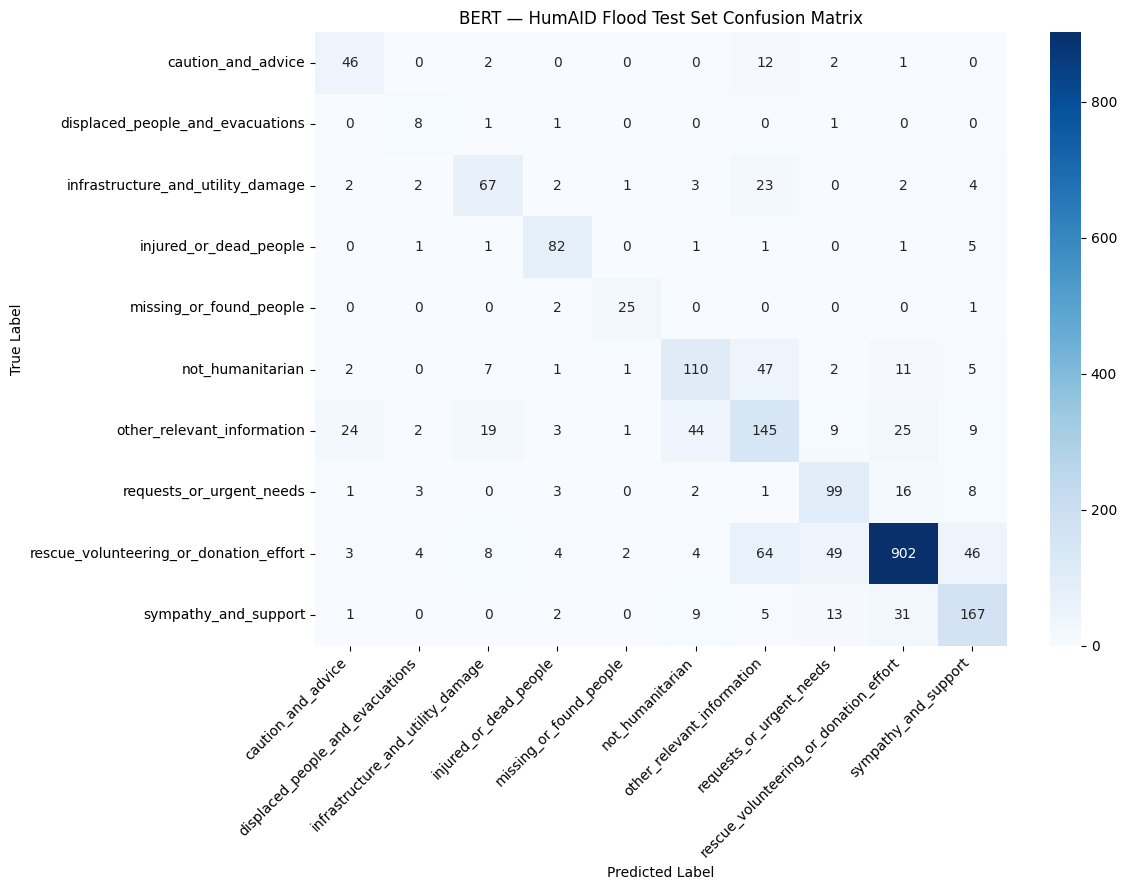

Classification report saved:
/content/drive/MyDrive/CrisisWeave_Project/04_Results/NLP/BERT_HumAID_Flood_classification_report.csv


In [46]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.title("BERT — HumAID Flood Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Save classification report
report_dict = classification_report(
    true_labels,
    predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = os.path.join(
    BERT_RESULTS_DIR,
    "BERT_HumAID_Flood_classification_report.csv"
)

report_df.to_csv(report_path)

print("Classification report saved:")
print(report_path)

In [45]:
import os
import shutil

# OLD runtime location
OLD_PROJECT_DIR = "/content/drive/MyDrive/CrisisWeave_Project"

# REAL Google Drive location
NEW_PROJECT_DIR = "/content/gdrive/MyDrive/CrisisWeave_Project"

# Source folders
OLD_BERT_DIR = os.path.join(
    OLD_PROJECT_DIR,
    "03_Models",
    "BERT",
    "HumAID_Flood_BERT"
)

OLD_NLP_DIR = os.path.join(
    OLD_PROJECT_DIR,
    "04_Results",
    "NLP"
)

# Destination folders
NEW_BERT_DIR = os.path.join(
    NEW_PROJECT_DIR,
    "03_Models",
    "BERT",
    "HumAID_Flood_BERT"
)

NEW_NLP_DIR = os.path.join(
    NEW_PROJECT_DIR,
    "04_Results",
    "NLP"
)

# Create destination directories
os.makedirs(NEW_BERT_DIR, exist_ok=True)
os.makedirs(NEW_NLP_DIR, exist_ok=True)

# Copy BERT model
shutil.copytree(
    OLD_BERT_DIR,
    NEW_BERT_DIR,
    dirs_exist_ok=True
)

# Copy NLP results
shutil.copytree(
    OLD_NLP_DIR,
    NEW_NLP_DIR,
    dirs_exist_ok=True
)

print("=" * 70)
print("BERT + NLP FILES COPIED TO REAL GOOGLE DRIVE")
print("=" * 70)

print("\nBERT destination:")
print(NEW_BERT_DIR)

print("\nNLP results destination:")
print(NEW_NLP_DIR)

BERT + NLP FILES COPIED TO REAL GOOGLE DRIVE

BERT destination:
/content/gdrive/MyDrive/CrisisWeave_Project/03_Models/BERT/HumAID_Flood_BERT

NLP results destination:
/content/gdrive/MyDrive/CrisisWeave_Project/04_Results/NLP


Save the final BERT model

In [25]:
# Save the best BERT model and tokenizer

trainer.save_model(BERT_MODEL_DIR)
tokenizer.save_pretrained(BERT_MODEL_DIR)

print("=" * 60)
print("FINAL BERT MODEL SAVED")
print("=" * 60)
print("Model:", BERT_MODEL_DIR)
print("Tokenizer saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FINAL BERT MODEL SAVED
Model: /content/drive/MyDrive/CrisisWeave_Project/03_Models/BERT/HumAID_Flood_BERT
Tokenizer saved successfully.


Save final test metrics

In [21]:
final_metrics = {
    "model": "bert-base-uncased",
    "dataset": "QCRI/HumAID-event-type (flood)",
    "num_classes": len(label_names),
    "test_samples": len(ds["test"]),
    "accuracy": test_results["eval_accuracy"],
    "macro_f1": test_results["eval_macro_f1"],
    "weighted_f1": test_results["eval_weighted_f1"],
    "test_loss": test_results["eval_loss"]
}

metrics_df = pd.DataFrame([final_metrics])

metrics_path = os.path.join(
    BERT_RESULTS_DIR,
    "BERT_HumAID_Flood_final_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("Final metrics saved:")
print(metrics_path)

print("\nFinal Test Performance:")
print(f"Accuracy    : {final_metrics['accuracy']:.4f}")
print(f"Macro F1    : {final_metrics['macro_f1']:.4f}")
print(f"Weighted F1 : {final_metrics['weighted_f1']:.4f}")

Final metrics saved:
/content/drive/MyDrive/CrisisWeave_Project/04_Results/NLP/BERT_HumAID_Flood_final_metrics.csv

Final Test Performance:
Accuracy    : 0.7457
Macro F1    : 0.6847
Weighted F1 : 0.7506
